# 📘 Notebook 07: Bike Sharing, When Do People Ride?

### Course: *From Questions to Answers: Classic Datasets, Fully Explored*
**Instructor:** Ioannis Tsioulis

*Dataset 7 · Capital Bikeshare, Washington D.C., 2011 and 2012 (17,379 hours)*

---

> 💡 **This notebook is already run.** Every table and chart below was produced by the code above it, and each result is followed by a comment that explains what it shows. You can read it without running anything. To experiment, choose **Runtime → Run all** in Colab; the whole notebook runs in about a minute. If you rerun it, numbers from the models may differ slightly, because Colab may have newer library versions.

## 🎯 Learning objectives

By the end of this notebook you will be able to:

- Load a file from inside a **zip archive** on the web
- Explore data **in time**: daily, weekly and seasonal patterns and a long-term **trend**
- Find **gaps in time** that do not appear as missing values
- Recognise columns that **contain the answer** and must never be used as features
- Explain why a **random split leaks the future** in time data, and evaluate a model honestly with a **time split**
- Compare a model with a simple **seasonal baseline**

> **Prerequisites:** [Notebook 03: House Prices](https://colab.research.google.com/github/giannis00/giannis00.github.io/blob/main/assets/jupyter/from-questions-to-answers/03_house_prices.ipynb) for regression and the mean absolute error.
>
> 🔭 **Why this notebook matters:** sales per day, electricity per hour, visitors per minute: a huge share of real data is a **count over time**. Time changes the rules of analysis. Rows are no longer independent, the same hour repeats with a rhythm, the world slowly changes, and a model must predict a future it has never seen. This dataset, prepared by Hadi Fanaee-T and João Gama from the logs of Washington's bike sharing system, is the classic first time dataset.

## 0. The question

For every hour of 2011 and 2012, the system recorded how many bikes were rented, split into **casual** users (who pay per ride) and **registered** members, together with the date, the hour, the weather and the temperature.

**Our question:** *When do people ride, and how well can we predict next season's demand?* More precisely:

1. What are the daily, weekly and seasonal rhythms of demand?
2. Who rides when: members or casual users?
3. How well can a model predict demand in a period it has never seen?

In [1]:
import warnings
warnings.filterwarnings("ignore")

import io
import zipfile
import urllib.request

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.precision", 3)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 80

## 1. Loading a file from a zip archive

The UCI repository publishes the data as a **zip archive** containing three files. `read_csv` cannot read a file inside a zip that holds several files, so we download the archive into memory, open it with Python's `zipfile` module and read the file we want.

In [2]:
URL = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"
archive = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(URL).read()))
print(archive.namelist())
df = pd.read_csv(archive.open("hour.csv"), parse_dates=["dteday"])
print(df.shape)
df.head()

['Readme.txt', 'day.csv', 'hour.csv']
(17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.288,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.273,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.273,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.288,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.288,0.75,0.0,0,1,1


**What we see.** The archive holds a description (`Readme.txt`), one row per day (`day.csv`) and one row per hour (`hour.csv`), which we use. 17,379 hours and 17 columns:
- **Time:** `dteday` (date), `season` (1 winter to 4 autumn), `yr` (0 = 2011, 1 = 2012), `mnth`, `hr` (0 to 23), `weekday`, `holiday`, `workingday`.
- **Weather:** `weathersit` (1 clear to 4 heavy rain or snow), `temp`, `atemp` ("feels like" temperature), `hum` (humidity), `windspeed`, all **already scaled** to 0 to 1 (the temperature was divided by 41 °C).
- **Counts:** `casual`, `registered` and their sum `cnt`, the total rentals in that hour.

## 2. Hidden gaps and columns that contain the answer

In [3]:
print("Missing values:", df.isna().sum().sum())
expected = 731 * 24
print("Hours in two years (2011 and 2012):", expected, "  rows in the file:", len(df), "  hours absent:", expected - len(df))

Missing values: 0
Hours in two years (2011 and 2012): 17544   rows in the file: 17379   hours absent: 165


**What we see.** pandas finds **no** missing values, yet **165 hours** are absent: two years have 731 days, or 17,544 hours, and the file has 17,379 rows. In time data, a gap is often a **missing row**, not an empty cell. The README explains some of them (a hurricane closed the system for parts of two days in 2012, for example); others are hours with no rentals at all that were simply not written down. For the patterns below this does not matter much, but any method that assumes "the next row is the next hour" would silently go wrong.

In [4]:
print("Is cnt always casual + registered?", (df["cnt"] == df["casual"] + df["registered"]).all())

Is cnt always casual + registered? True


**What we see.** `cnt` is **exactly** `casual + registered` in every row. If we used `casual` and `registered` as features to predict `cnt`, a model would score perfectly, and be useless: at prediction time we do not know them. These columns **contain the answer**. They are perfect for exploration and forbidden as features. This kind of leakage is common in business data (for example, using "date of cancellation" to predict who will cancel).

## 3. The rhythm of a day

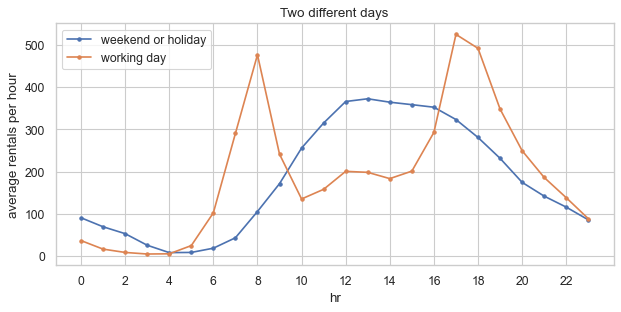

,weekend or holiday,working day
hr,,
3,26.0,5.0
8,106.0,477.0
12,366.0,201.0
17,324.0,525.0
18,281.0,492.0
23,86.0,89.0


In [5]:
by_hour = df.groupby(["workingday", "hr"])["cnt"].mean().unstack(0)
by_hour.columns = ["weekend or holiday", "working day"]
by_hour.plot(figsize=(9, 4), marker="o", ms=3)
plt.ylabel("average rentals per hour")
plt.xticks(range(0, 24, 2))
plt.title("Two different days")
plt.show()
by_hour.loc[[3, 8, 12, 17, 18, 23]].round(0)

**What we see.** Two completely different shapes:
- **Working days** have two sharp peaks: about **477** rentals at **8:00** and about **525** at **17:00** (492 at 18:00), with a dip in between. These are **commuters**.
- **Weekends and holidays** have one broad hill around midday (about **366** at 12:00), and almost nothing at 8:00. These are **leisure** riders.

An average over all days would show a shape that matches **neither** kind of day. Like the red and white wines and the three penguin species, the data contains two groups that must be looked at separately.

In [6]:
df.groupby("workingday")[["casual", "registered"]].mean().round(0).rename(index={0: "weekend or holiday", 1: "working day"})

,casual,registered
workingday,,
weekend or holiday,57.0,124.0
working day,26.0,168.0


**What we see.** The two kinds of day also have different **riders**. On working days, registered members make about **168** rentals per hour on average against **26** for casual users; at weekends, members ride less (**124**) and casual users twice as much (**57**). Overall, casual users make **19%** of all rentals. The commuter peaks belong to members; the weekend hill is shared.

## 4. Seasons, weather and a trend

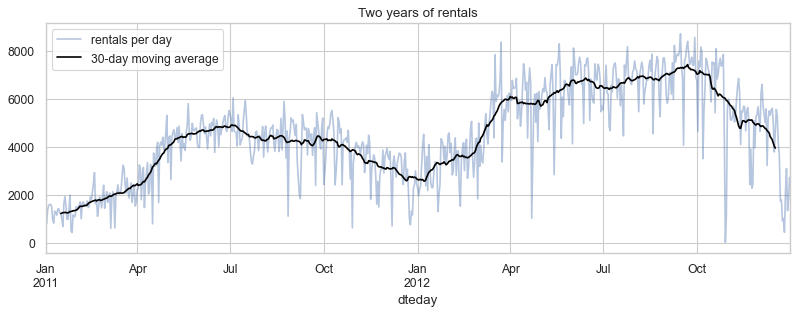

Average rentals per hour: 2011 144  2012 235


In [7]:
daily = df.groupby("dteday")["cnt"].sum()
plt.figure(figsize=(12, 3.8))
daily.plot(alpha=0.4, label="rentals per day")
daily.rolling(30, center=True).mean().plot(color="black", label="30-day moving average")
plt.legend()
plt.title("Two years of rentals")
plt.show()
print("Average rentals per hour: 2011", round(df.loc[df["yr"] == 0, "cnt"].mean()), " 2012", round(df.loc[df["yr"] == 1, "cnt"].mean()))

**What we see.** Two patterns on top of each other:
- A **seasonal** wave: low in winter, high from late spring to early autumn, every year.
- A **trend**: 2012 is clearly above 2011, about **235** rentals per hour against **144**, an increase of more than 60%. The system was growing: more stations, more members.

The trend matters for prediction. A model that learned only from 2011 would expect 2012 to look like 2011, and would be badly wrong. We come back to this in Section 5.

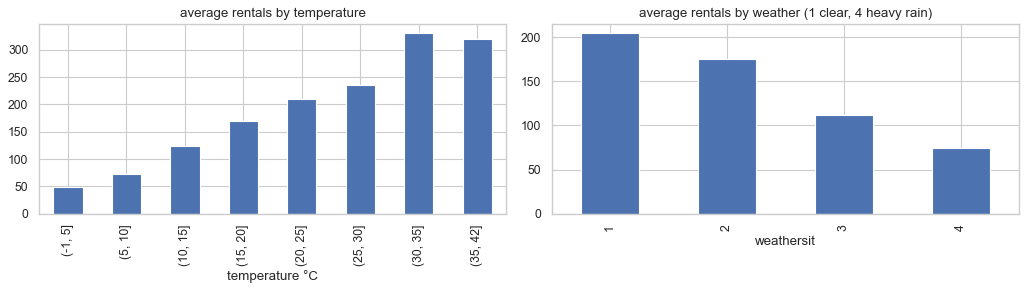

weathersit        1       2       3     4
mean          205.0   175.0   112.0  74.0
hours       11413.0  4544.0  1419.0   3.0
Correlation of temp and atemp: 0.988


In [8]:
temperature = (df["temp"] * 41).rename("temperature °C")
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
df.groupby(pd.cut(temperature, [-1, 5, 10, 15, 20, 25, 30, 35, 42]))["cnt"].mean().plot.bar(ax=axes[0], title="average rentals by temperature")
df.groupby("weathersit")["cnt"].mean().plot.bar(ax=axes[1], title="average rentals by weather (1 clear, 4 heavy rain)")
plt.tight_layout()
plt.show()
print(df.groupby("weathersit")["cnt"].agg(mean="mean", hours="size").round(0).T)
print("Correlation of temp and atemp:", round(df["temp"].corr(df["atemp"]), 3))

**What we see.**
- **Temperature:** rentals rise steadily from about **49** per hour below 5 °C to over **300** above 30 °C, and level off at the very top.
- **Weather:** clear hours average about **205** rentals, light rain **112**, and the 3 hours of heavy rain in the data **74**. Three hours are far too few to trust that last number.
- `temp` and `atemp` are almost the same column (correlation **0.988**): redundancy again.

Notice that temperature, season and month all describe the same yearly cycle from different angles. This is why a model can still predict well even if we remove one of them.

## 5. Predicting demand honestly

### Intuition first
In Notebooks 01 to 06 we shuffled the rows and split them at random. For time data that is a mistake. With a random split, the model is trained on, say, 9:00 and 11:00 on a Tuesday and tested on 10:00 that same Tuesday: it "predicts" an hour whose neighbours it has already seen. In real use, a model must predict **the future** from **the past**.

The honest test: **train on everything before 1 July 2012, and test on the second half of 2012.**

In [9]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import mean_absolute_error

features = ["season", "yr", "mnth", "hr", "holiday", "weekday", "workingday",
            "weathersit", "temp", "atemp", "hum", "windspeed"]
X, y = df[features], df["cnt"]
forest = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)

random_split = cross_val_predict(forest, X, y, cv=KFold(5, shuffle=True, random_state=42))
train = df["dteday"] < "2012-07-01"
test = ~train
time_split = forest.fit(X[train], y[train]).predict(X[test])

print("Average rentals per hour in the test period:", round(y[test].mean()))
print("Error with a RANDOM split (misleading):", round(mean_absolute_error(y, random_split), 1))
print("Error with a TIME split (honest):     ", round(mean_absolute_error(y[test], time_split), 1))

Average rentals per hour in the test period: 254
Error with a RANDOM split (misleading): 25.3
Error with a TIME split (honest):      45.9


**What we see.** The same forest, with the same features, has an error of **25** rentals per hour when tested on shuffled hours, and **46** when tested honestly on the second half of 2012, almost **twice** as much. The random split was not testing prediction; it was testing interpolation between hours the model had already seen. In a report to the bike company, only the second number may be given.

An error of 46 on an average of **254** rentals per hour is about 18%.

In [10]:
when = pd.to_datetime(df["dteday"]) + pd.to_timedelta(df["hr"], unit="h")
series = pd.Series(df["cnt"].values, index=when)
last_week = series.shift(freq="7D").reindex(series.index)
mask = test.values & last_week.notna().values
print("Seasonal baseline 'same hour, one week earlier':", round(mean_absolute_error(series[mask], last_week[mask]), 1))

Seasonal baseline 'same hour, one week earlier': 63.2


**What we see.** Is 46 good? Compare it with the simplest forecast a person would make: **the same hour one week earlier**. That baseline misses by **63** rentals per hour. The forest beats it clearly, mainly by using the weather: it knows that a rainy Tuesday will be quieter than last Tuesday was.

For time data, this "same time last period" baseline plays the role that "always the majority class" played for classification: the bar every model must clear.

In [11]:
no_year = [f for f in features if f != "yr"]
blind = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1).fit(X.loc[train, no_year], y[train])
print("Time split error WITHOUT the year column:", round(mean_absolute_error(y[test], blind.predict(X.loc[test, no_year])), 1))

Time split error WITHOUT the year column: 90.9


**What we see.** Remove the `yr` column, and the honest error jumps from **46** to **91**. Without the year, the model cannot tell busy 2012 from quiet 2011, and averages them. A forest **cannot extrapolate**: it can only predict values like those it has seen. The `yr` column gives it a crude way to follow the growth trend. A real forecasting system models the trend explicitly, and must be retrained as the system keeps growing.

## 6. Answer to the question

*When do people ride, and how well can we predict demand?*

1. **Two kinds of day:** working days have commuter peaks at 8:00 and 17:00 to 18:00, carried by registered members; weekends have a midday hill with twice as many casual riders.
2. **Weather and season:** demand rises steadily with temperature and falls sharply in rain.
3. **Growth:** 2012 was more than 60% busier than 2011.
4. **Honest prediction:** trained on the past and tested on the next six months, a random forest misses by about **46 rentals per hour** (about 18%), better than the "same hour last week" baseline (63). A random split would have claimed 25.
5. **Two hidden traps:** 165 hours are absent from the file without any empty cell, and two columns (`casual`, `registered`) add up to the answer.

## 🚀 Going further (for experienced students)

### A. Lag features: using the recent past
Strong forecasting notebooks add **lag features**: the count at the same hour **one day** and **one week** earlier. If the forecast is made a day ahead, both are known at prediction time, so they are fair to use. They carry the trend and recent changes that the calendar columns cannot.

In [12]:
lagged = df.copy()
lagged["when"] = when.values
counts = pd.Series(lagged["cnt"].values, index=lagged["when"])
lagged["same_hour_yesterday"] = counts.shift(freq="1D").reindex(lagged["when"]).values
lagged["same_hour_last_week"] = counts.shift(freq="7D").reindex(lagged["when"]).values
lagged = lagged.dropna(subset=["same_hour_yesterday", "same_hour_last_week"])
lag_features = no_year + ["same_hour_yesterday", "same_hour_last_week"]
tr = lagged["dteday"] < "2012-07-01"
lag_model = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1).fit(lagged.loc[tr, lag_features], lagged.loc[tr, "cnt"])
print("Time split error with lag features (and no year column):",
      round(mean_absolute_error(lagged.loc[~tr, "cnt"], lag_model.predict(lagged.loc[~tr, lag_features])), 1))

Time split error with lag features (and no year column): 49.6


**What we see.** With the two lag features **instead of** the year column, the honest error is **49.6** rentals per hour: almost as good as the model that was told the year (46), and far better than the model without it (91). The lags give the model the current **level** of demand, so it no longer needs to be told which year it is, and it would keep working in a third, even busier year, where the `yr` column would mean nothing.

### B. Several honest splits: `TimeSeriesSplit`
One time split gives one number. **`TimeSeriesSplit`** makes several: train on the first part and test on the next, then train on more and test on the following part, always moving forward in time.

In [13]:
from sklearn.model_selection import TimeSeriesSplit

ordered = lagged.sort_values("when")
errors = []
for tr_idx, te_idx in TimeSeriesSplit(n_splits=4).split(ordered):
    m = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1).fit(ordered.iloc[tr_idx][lag_features], ordered.iloc[tr_idx]["cnt"])
    errors.append(mean_absolute_error(ordered.iloc[te_idx]["cnt"], m.predict(ordered.iloc[te_idx][lag_features])))
print("Error on each of the 4 forward splits:", [round(e, 1) for e in errors])

Error on each of the 4 forward splits: [41.2, 37.5, 53.6, 46.7]


**What we see.** Four forward splits give errors of **41**, **38**, **54** and **47**. The error depends on **which period** is tested (the later, busier periods are harder in absolute numbers), so a single split is one draw from a range. Reporting the spread is more honest than reporting one number.

## ⚠️ Common pitfalls

- **Shuffling time data.** A random split leaks the future into training and makes models look far better than they are. Split by time.
- **Using columns that are part of the answer.** `casual + registered = cnt`; at prediction time you have neither.
- **Assuming one row per period.** Check the number of rows against the calendar; gaps are often missing rows, not empty cells.
- **Averaging different kinds of days together.** The average day matches neither a working day nor a weekend.
- **Ignoring the trend.** A model trained in a smaller year will under-predict a bigger one, and tree-based models cannot extrapolate beyond what they saw.
- **Skipping the seasonal baseline.** "Same time last week" is easy to compute and often hard to beat.

## ✏️ Exercises

### Exercise 1 (Members against casual riders by hour)
Plot the average number of **casual** and **registered** rentals by hour, for working days only. At what hour do casual users peak?

In [14]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
work = df[df["workingday"] == 1].groupby("hr")[["casual", "registered"]].mean()
work.plot(figsize=(9, 4), marker="o", ms=3, title="Working days: who rides when")
plt.show()
print("casual peak hour:", work["casual"].idxmax(), "  registered peak hour:", work["registered"].idxmax())
```

*Both groups peak at 17:00, but in very different ways. Casual riders rise slowly through the day (about 22 rentals per hour at 8:00, 41 at noon, 57 at 17:00), with no real morning peak; members have the sharp double peak of commuting. The commuter rhythm belongs to the members.*
</details>

### Exercise 2 (A daily forecast)
Use the **day** file (`day.csv` in the same archive). Train a random forest on days before 1 July 2012 and test on the rest, using the same features without `hr`. What is the error as a percentage of the average daily count?

In [15]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
days = pd.read_csv(archive.open("day.csv"), parse_dates=["dteday"])
day_features = [f for f in features if f != "hr"]
past = days["dteday"] < "2012-07-01"
model = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1).fit(days.loc[past, day_features], days.loc[past, "cnt"])
error = mean_absolute_error(days.loc[~past, "cnt"], model.predict(days.loc[~past, day_features]))
print("daily error:", round(error), " as % of the average day:", round(100 * error / days.loc[~past, "cnt"].mean(), 1))
```

*Daily totals are smoother than hours, because hourly ups and downs cancel out, so the relative error is usually smaller. The level of detail of a forecast should match the decision it serves: staffing is planned by the day, rebalancing bikes by the hour.*
</details>

### Exercise 3 (How bad is the gap problem?)
Find the **dates** with fewer than 24 hours in the file. How many are there, and which month has the most?

In [16]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
hours_per_day = df.groupby("dteday").size()
short = hours_per_day[hours_per_day < 24]
print(len(short), "days with missing hours")
print(short.groupby(short.index.to_period("M")).size().sort_values(ascending=False).head(3))
```

*Of the 76 short days, 62 miss only **one** hour, typically a quiet early-morning hour with no rentals, and they are most common in the first, quieter months of 2011. A handful of days lost 6 to 23 hours at once; those are the closures described in the README.*
</details>

## 🔑 Key takeaways

- Time data has **rhythms** (day, week, season) and a **trend**; explore each one.
- Different **kinds of periods** (working day, weekend) can have completely different shapes; do not average them together.
- **Gaps** in time are often missing rows; compare the row count with the calendar.
- Never use columns that **are part of the answer** as features.
- Evaluate forecasts with a **time split** and compare them with a **seasonal baseline** such as "same hour last week".
- Tree models **cannot extrapolate** a growing trend on their own.

---
**Next:** *Notebook 08: Fashion-MNIST*, where every row is an image of 784 pixels, and we explore pictures before any deep learning.

---
*© Ioannis Tsioulis. *From Questions to Answers: Classic Datasets, Fully Explored*. Prepared for educational use.*